
# Lab 9: Quantun Computing - Rabi Oscillations

Nombre estudiante: Alejandro Montoya Ruiz

c.c:1000411756

In [47]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator


## Exercise 1: $NH_3$ molecule

An example of the quantum oscillations in two-level systems may be rather unexpected; for example, the ammonium molecule 

![NH3](https://i.imgur.com/tgrUmMi.png)

 It has two symmetric states that differ by the inversion of the nitrogen atom relative to the plane of the three hydrogen atoms, which are weakly coupled due to quantum-mechanical tunneling of the nitrogen atom through the plane of the hydrogen atoms. Since for this particular molecule, in the absence of external fields, the level splitting $\Delta E$ corresponds to an experimentally convenient frequency $\Omega/2\pi\approx$ 24.79 GHz.

 1. Supose a detuning frequency $\Omega_R/2$.
 2. Compute the Rabi frequency for NH3 molecule in Hz and do a plot of the Rabi oscillation. Supose that the initial state is $\ket{2}$.
 


 [references](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems)

La molécula de amoníaco $NH_{3}$ en ausencia de campos externos su separación energetica de niveles (dos estados) es : 

$$\Delta E = h\nu_{0} = \hbar \Omega$$

como $\hbar = \frac{h}{2\pi}$ entoncess despejando la frecuencia da:

$$\nu_{0} = \frac{\Delta E}{h} = \frac{\Omega_{0}}{2\pi}= 24.79\times 10^{9}$$

La frecuencia angular generalizada de Rabi es:

$$\Omega = \sqrt{\Omega_{0}^2 + \delta^2}$$

donde: 
*   $\Omega_{0}$  es la frecuencia angular de acoplamiento ($\Omega_{0} = 2\pi\nu_{0}$) (frecuencia angular de Rabi en resonancia)
*   $\delta$ Frecuencia angular de desintonización (detuning) 
*   $\Omega$ La frecuencia efectiva o generalizada de Rabi

Por tanto la probabilidad de ocupación o transición (Ocilación de Rabi) en un sistema qu inicia en el estado $\ket{2}$

$$W_1(t) = \frac{\Omega_{0}^2}{\Omega_{0}^2 + \delta^2} \sin{\frac{\Omega t}{2}}^2 = \frac{\Omega_{0}^2}{\Omega^2} \sin{\frac{\Omega t}{2}}^2 $$

Nota: En la referencias Likharev absorbe el 1/2 para que quede seno al cuadradado pero es lo mismo
[Time-Dependent_Peturbations](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_%28Likharev%29/06%3A_Perturbative_Approaches/6.05%3A_Time-dependent_Perturbations?utm_source=chatgpt.com)

Y la probabilidad de permanecer en el estado inicial es:

$$W_2(t) = 1 - W_1(t)$$

In [31]:
nu_0 = 24.79e9  # Frecuencia Hz
Omega_0 = 2 * np.pi * nu_0 # Frecuencia angular 
delta = Omega_0 / 2 # Frecuencia de desintonixación

In [ ]:
Omega = np.sqrt(Omega_0**2 + delta**2) # rad/sg
nu = Omega / (2 * np.pi) # Hz
W_1_max = Omega_0**2 / Omega**2 # Probabilidad maxima
T = 2 * np.pi / Omega

print(f"Ω₀ = {Omega_0:.4e} rad/s")
print(f"δ = {delta:.4e} rad/s$")
print(f"Ω = {Omega:.4e} rad/s")
print(f"Probalidad Maxima = {W_1_max:.4f}") # 4/5 de la definición de Omega
print(f"Frecuencia de Oscilación = {nu/1e9:.4f} GHz")
print(f"Periodo de la Oscilación= {T:.4e} s")

Ω₀ = 1.5576e+11 rad/s
δ = 7.7880e+10 rad/s$
Ω = 1.7415e+11 rad/s
Probalidad Maxima = 0.8000
Frecuencia de Oscilación = 27.7161 GHz
Periodo de la Oscilación= 3.6080e-11 s


In [20]:
t = np.linspace(0, 3*T, 1500)
W_1 = W_1_max * np.sin(Omega * t / 2)**2
W_2 = 1 - W_1

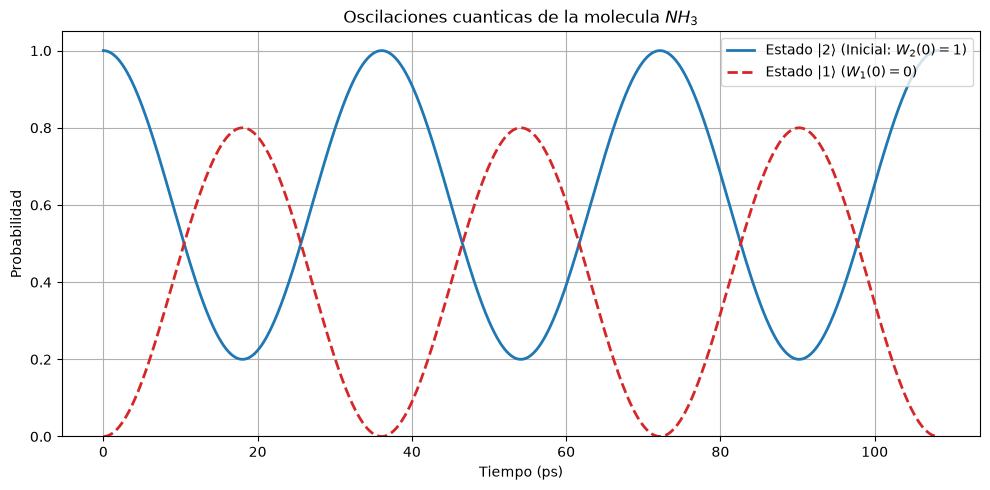

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(t * 1e12, W_2, label=r"Estado $|2\rangle$ (Inicial: $W_2(0)=1$)", color="#1f77b4", linewidth=2)
plt.plot(t * 1e12, W_1, label=r"Estado $|1\rangle$ ($W_1(0)=0$)", color="#d62728", linestyle="--", linewidth=2)
plt.xlabel('Tiempo (ps)')
plt.ylabel('Probabilidad')
plt.title(r'Oscilaciones cuanticas de la molecula $NH_3$')
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()

## Exercise: Bell state


1. Creates a quantum circuit for two qubits, consisting of the quantum gates needed to create a `Bell state`  (two entangled qubits). The quantum circuit then terminates with quantum measurements, extracting one bit from each qubit.

Este punto esta en Sesiones/QC/5_qiskit.ipynb 

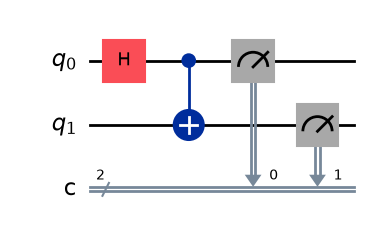

In [43]:
qc = QuantumCircuit(2, 2)
qc.h(0) # Compuerta Hadamard (Superposición del qubit 0)
qc.cx(0, 1) # Compuerta CNOT (Control del qubit 0 al qubit 1)
qc.measure([0, 1], [0, 1])  # Mide los dos qubits y los proyecta sobre el bit clásico que se especifica
qc.draw(output='mpl',plot_barriers=True)

In [45]:
simulador = AerSimulator()
resultado = simulador.run(qc, shots=1000).result()
conteos = resultado.get_counts()

print("Resultados (2 qubits):", conteos)

Resultados (2 qubits): {'00': 499, '11': 501}


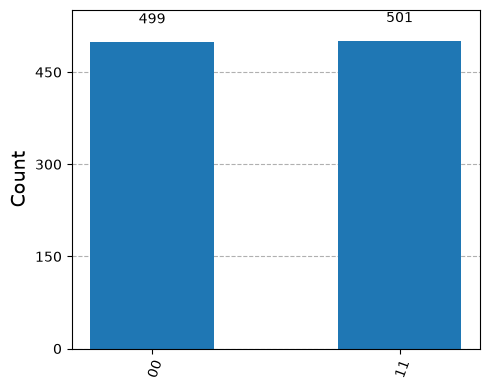

In [48]:
plot_histogram(resultado.get_counts(qc),figsize=(5,4))

2. Add a third qubit by changing to QuantumCircuit(3), and add a second CX gate with qc.cx(1,2). The measurements should then change to 000 and 111, which means all three of these qubits have been entangled.

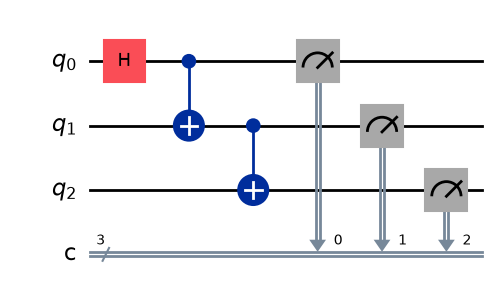

In [54]:
qc_2 = QuantumCircuit(3, 3)
qc_2.h(0)
qc_2.cx(0, 1)
qc_2.cx(1, 2)
qc_2.measure([0, 1, 2], [0, 1, 2])
qc_2.draw(output='mpl',plot_barriers=True)

In [59]:
simulador = AerSimulator()
resultado_2 = simulador.run(qc_2, shots=1000).result()
conteos_2 = resultado.get_counts()
print("Resultados (3 qubits):", conteos_2)

Resultados (3 qubits): {'00': 499, '11': 501}


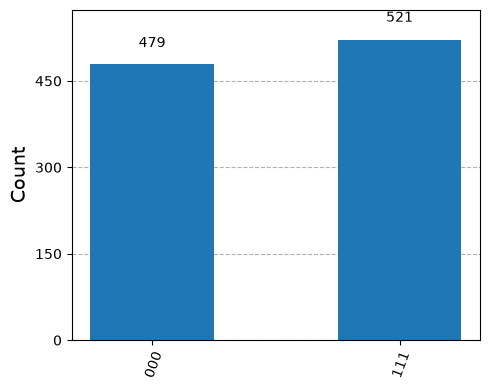

In [58]:
plot_histogram(resultado_2.get_counts(qc_2),figsize=(5,4))

3. See your results shift by adding qc.x(1) to the end of the circuit.

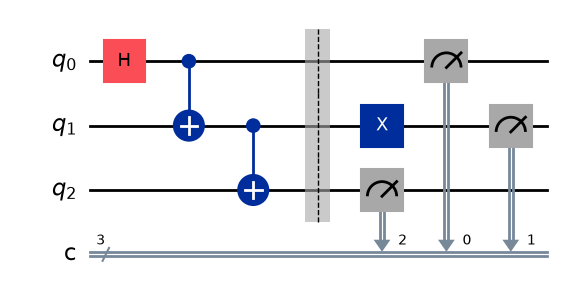

In [62]:
qc_3 = QuantumCircuit(3, 3)
qc_3.h(0)
qc_3.cx(0, 1)
qc_3.cx(1, 2)
qc_3.barrier()
qc_3.x(1)
qc_3.measure([0, 1, 2], [0, 1, 2])
qc_3.draw(output='mpl',plot_barriers=True)

In [63]:
simulador = AerSimulator()
resultado_3 = simulador.run(qc_3, shots=1000).result()
conteos_3 = resultado.get_counts()
print("Resultados (3 qubits):", conteos_3)

Resultados (3 qubits): {'00': 499, '11': 501}


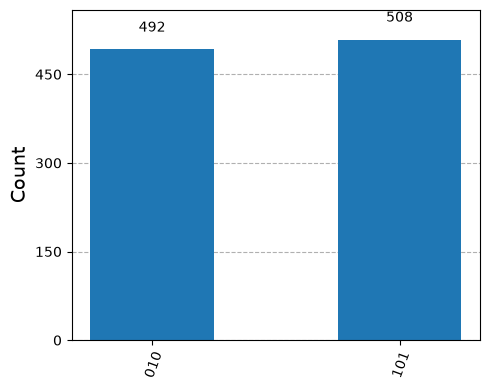

In [64]:
plot_histogram(resultado_3.get_counts(qc_3),figsize=(5,4))